# AISE 4010 Course Project – Stage 1 (Lab 6)
## Beijing PM2.5: one-hour-ahead forecasting with a baseline, an MLP and a 1D CNN

In [1]:
import os
import time
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

SEED = 42
tf.keras.utils.set_random_seed(SEED)
print("Seed:", SEED)

Seed: 42


## 1. Data

| | |
|---|---|
| Source | UCI Beijing PM2.5 data, `pollution.csv` (dataset #23) |
| Target | `pm2.5` |
| Unit | µg/m³ |
| Native frequency | hourly |
| Resampling rule | none needed (hourly index checked below) |
| Horizon | 1 hour |
| Lookback | 24 hours |
| Split | chronological 60% train / 20% validation / 20% test |

In [2]:
DATA_URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pollution.csv"
DATA_FILE = "data/pollution.csv"

if not os.path.exists(DATA_FILE):
    urllib.request.urlretrieve(DATA_URL, DATA_FILE)

df = pd.read_csv(DATA_FILE)
df["DATE"] = pd.to_datetime(df[["year", "month", "day", "hour"]])
df = df.sort_values("DATE").set_index("DATE")

series = df["pm2.5"].copy()

In [3]:
is_na = series.isna()

print("Rows:", len(df))
print("Coverage:", df.index.min(), "to", df.index.max())
print("Duplicate timestamps:", df.index.duplicated().sum())
print("Gaps in the hourly index:", (df.index.to_series().diff().dropna() != pd.Timedelta(hours=1)).sum())
print("Missing pm2.5:", is_na.sum(), f"({is_na.mean():.1%})")
print("Leading rows with no reading:", series.index.get_loc(series.first_valid_index()))
print()
print(series.describe())

assert df.index.is_unique and df.index.is_monotonic_increasing

Rows: 43824
Coverage: 2010-01-01 00:00:00 to 2014-12-31 23:00:00
Duplicate timestamps: 0
Gaps in the hourly index: 0
Missing pm2.5: 2067 (4.7%)
Leading rows with no reading: 24

count    41757.000000
mean        98.613215
std         92.050387
min          0.000000
25%         29.000000
50%         72.000000
75%        137.000000
max        994.000000
Name: pm2.5, dtype: float64


The first 24 rows have no reading, so the series starts at the first observed value.

In [4]:
series = series.loc[series.first_valid_index():]
print("Series used:", series.index.min(), "to", series.index.max(), "|", len(series), "hours")

Series used: 2010-01-02 00:00:00 to 2014-12-31 23:00:00 | 43800 hours


## 2. Chronological split
Split the raw series first. No imputation, scaling or windows before this step.

In [5]:
n = len(series)
train_end = int(0.60 * n)
val_end = int(0.80 * n)

train_raw = series.iloc[:train_end].copy()
val_raw   = series.iloc[train_end:val_end].copy()
test_raw  = series.iloc[val_end:].copy()

split_table = pd.DataFrame({
    "start": [s.index.min() for s in (train_raw, val_raw, test_raw)],
    "end": [s.index.max() for s in (train_raw, val_raw, test_raw)],
    "hours": [len(s) for s in (train_raw, val_raw, test_raw)],
    "missing": [s.isna().sum() for s in (train_raw, val_raw, test_raw)]
}, index=["Train", "Validation", "Test"])
display(split_table)

,start,end,hours,missing
Train,2010-01-02,2012-12-31 23:00:00,26280,1862
Validation,2013-01-01,2013-12-31 23:00:00,8760,82
Test,2014-01-01,2014-12-31 23:00:00,8760,99


## 3. Exploratory analysis

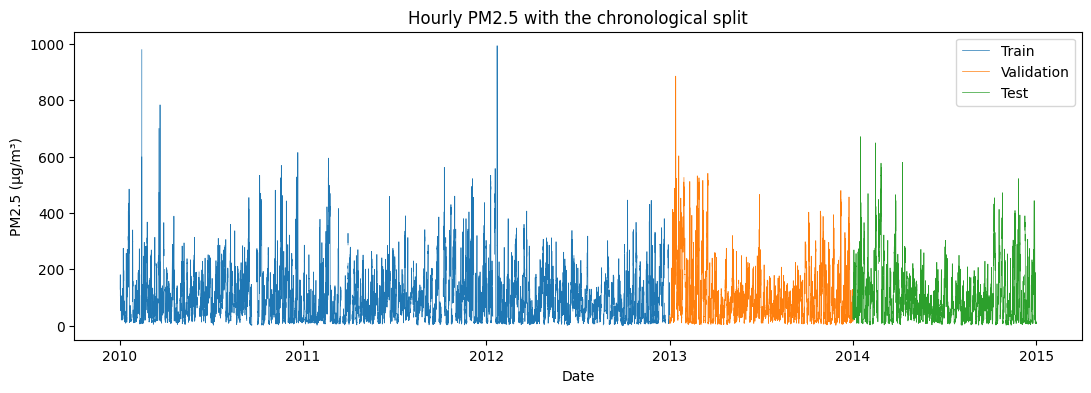

In [6]:
plt.figure(figsize=(13, 4))
plt.plot(train_raw, linewidth=0.5, label="Train")
plt.plot(val_raw, linewidth=0.5, label="Validation")
plt.plot(test_raw, linewidth=0.5, label="Test")
plt.xlabel("Date")
plt.ylabel("PM2.5 (µg/m³)")
plt.title("Hourly PM2.5 with the chronological split")
plt.legend()
plt.show()

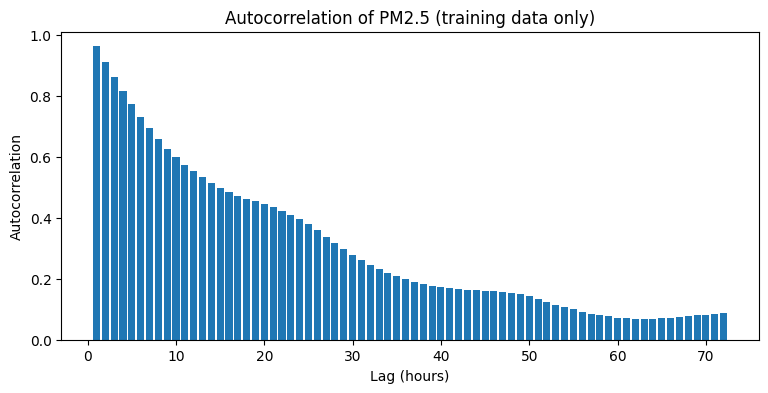

In [7]:
acf = [train_raw.autocorr(lag) for lag in range(1, 73)]

plt.figure(figsize=(9, 4))
plt.bar(range(1, 73), acf)
plt.xlabel("Lag (hours)")
plt.ylabel("Autocorrelation")
plt.title("Autocorrelation of PM2.5 (training data only)")
plt.show()

## 4. Imputation, scaling and windows
Forward fill after splitting. A validation/test block may inherit the last value of the block before it, because that past observation is already known.

In [8]:
train = train_raw.ffill()

val = pd.concat([train.iloc[-1:], val_raw]).ffill().iloc[1:]
test = pd.concat([val.iloc[-1:], test_raw]).ffill().iloc[1:]

print(train.isna().sum(), val.isna().sum(), test.isna().sum())
assert train.notna().all() and val.notna().all() and test.notna().all()

0 0 0


In [9]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

train_scaled = scaler.fit_transform(
    train.to_numpy().reshape(-1, 1)
).ravel()

val_scaled = scaler.transform(
    val.to_numpy().reshape(-1, 1)
).ravel()

test_scaled = scaler.transform(
    test.to_numpy().reshape(-1, 1)
).ravel()

In [10]:
def make_windows(values, lookback):
    X, y = [], []
    for i in range(lookback, len(values)):
        X.append(values[i-lookback:i])
        y.append(values[i])
    return np.asarray(X), np.asarray(y)

LOOKBACK = 24

X_train, y_train = make_windows(train_scaled, LOOKBACK)
X_val,   y_val   = make_windows(val_scaled, LOOKBACK)
X_test,  y_test  = make_windows(test_scaled, LOOKBACK)

val_observed = val_raw.iloc[LOOKBACK:].notna().to_numpy()
test_observed = test_raw.iloc[LOOKBACK:].notna().to_numpy()
X_val, y_val = X_val[val_observed], y_val[val_observed]
X_test, y_test = X_test[test_observed], y_test[test_observed]

print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_val:  ", X_val.shape,   "y_val:", y_val.shape)
print("X_test: ", X_test.shape,  "y_test:", y_test.shape)
print("CNN input (add channel axis):", X_train[..., np.newaxis].shape)
print("\nFirst training input:", X_train[0])
print("First training target:", y_train[0])

X_train: (26256, 24) y_train: (26256,)
X_val:   (8654, 24) y_val: (8654,)
X_test:  (8637, 24) y_test: (8637,)
CNN input (add channel axis): (26256, 24, 1)

First training input: [0.36859129 0.58395565 0.70864028 0.95800954 0.47060598 0.14189196
 0.09655209 0.31191645 0.26657659 0.40259619 0.49327592 0.62929552
 0.58395565 0.76531511 0.69730531 0.65196545 0.70864028 0.76531511
 0.83332491 0.59529062 0.65196545 0.76531511 0.67463538 0.33458639]
First training target: -0.07347240746272389


## 5. Naive baseline
Predict the next hour with the latest available hour, which is the last value of each 24-hour window.

In [11]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

def inverse_1d(values, fitted_scaler):
    return fitted_scaler.inverse_transform(
        np.asarray(values).reshape(-1, 1)
    ).ravel()

val_actual = inverse_1d(y_val, scaler)

val_naive_scaled = X_val[:, -1]
val_naive = inverse_1d(val_naive_scaled, scaler)

baseline_val_mae = mean_absolute_error(val_actual, val_naive)
baseline_val_rmse = mean_squared_error(val_actual, val_naive) ** 0.5

print("Naive validation MAE :", baseline_val_mae)
print("Naive validation RMSE:", baseline_val_rmse)

Naive validation MAE : 13.235035821585393
Naive validation RMSE: 24.896504052340262


## 6. MLP and 1D CNN with grid search
Both models use the same windows, loss (MSE), optimizer (Adam), batch size, early stopping and validation set. The best configuration is the one with the lowest validation RMSE.

```text
MLP: units = [16, 32], learning_rate = [0.01, 0.001]
CNN: filters = [8, 16], kernel_size = [3, 7]
```

In [12]:
from itertools import product
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Dense, Conv1D, MaxPooling1D, Flatten
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

def build_mlp(units, lr):
    model = Sequential([
        Input(shape=(LOOKBACK,)),
        Dense(units, activation="relu"),
        Dense(1)
    ])
    model.compile(optimizer=Adam(learning_rate=lr), loss="mse")
    return model

def build_1d_cnn(filters, kernel_size):
    model = Sequential([
        Input(shape=(LOOKBACK, 1)),
        Conv1D(filters=filters, kernel_size=kernel_size, activation="relu", padding="same"),
        MaxPooling1D(pool_size=2),
        Flatten(),
        Dense(16, activation="relu"),
        Dense(1)
    ])
    model.compile(optimizer=Adam(learning_rate=0.001), loss="mse")
    return model

In [13]:
grid = {
    "units": [16, 32],
    "lr": [0.01, 0.001]
}

mlp_results = []
mlp_histories = {}

for units, lr in product(grid["units"], grid["lr"]):

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    candidate = build_mlp(units, lr)

    es = EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    )

    candidate_history = candidate.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=50,
        batch_size=32,
        shuffle=False,
        callbacks=[es],
        verbose=0
    )

    pred_scaled = candidate.predict(X_val, verbose=0).ravel()
    pred = inverse_1d(pred_scaled, scaler)

    rmse = mean_squared_error(val_actual, pred) ** 0.5

    mlp_histories[(units, lr)] = candidate_history.history
    mlp_results.append({
        "units": units,
        "lr": lr,
        "validation_RMSE": rmse,
        "best_epoch": int(np.argmin(candidate_history.history["val_loss"])) + 1,
        "epochs_trained": len(candidate_history.history["loss"])
    })

mlp_results = pd.DataFrame(mlp_results).sort_values(
    ["validation_RMSE", "units", "lr"]
).reset_index(drop=True)

display(mlp_results)

best_units = int(mlp_results.iloc[0]["units"])
best_lr = float(mlp_results.iloc[0]["lr"])
best_epochs_mlp = int(mlp_results.iloc[0]["best_epoch"])

print("Best units:", best_units)
print("Best learning rate:", best_lr)
print("Final refit epochs (chosen on validation only):", best_epochs_mlp)

,units,lr,validation_RMSE,best_epoch,epochs_trained
0,32,0.001,24.268235,21,26
1,16,0.010,24.408584,7,12
2,32,0.010,24.486470,15,20
3,16,0.001,25.188316,8,13


Best units: 32
Best learning rate: 0.001
Final refit epochs (chosen on validation only): 21


In [14]:
filters_grid_1d = [8, 16]
kernel_grid_1d = [3, 7]

cnn_results = []
cnn_histories = {}

for filters, kernel_size in product(filters_grid_1d, kernel_grid_1d):

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    candidate = build_1d_cnn(filters, kernel_size)

    es = EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    )

    candidate_history = candidate.fit(
        X_train[..., np.newaxis], y_train,
        validation_data=(X_val[..., np.newaxis], y_val),
        epochs=50,
        batch_size=32,
        shuffle=False,
        callbacks=[es],
        verbose=0
    )

    pred_scaled = candidate.predict(X_val[..., np.newaxis], verbose=0).ravel()
    pred = inverse_1d(pred_scaled, scaler)

    rmse = mean_squared_error(val_actual, pred) ** 0.5

    cnn_histories[(filters, kernel_size)] = candidate_history.history
    cnn_results.append({
        "filters": filters,
        "kernel_size": kernel_size,
        "validation_RMSE": rmse,
        "best_epoch": int(np.argmin(candidate_history.history["val_loss"])) + 1,
        "epochs_trained": len(candidate_history.history["loss"])
    })

cnn_results = pd.DataFrame(cnn_results).sort_values(
    ["validation_RMSE", "filters", "kernel_size"]
).reset_index(drop=True)

display(cnn_results)

best_1d_filters = int(cnn_results.iloc[0]["filters"])
best_1d_kernel = int(cnn_results.iloc[0]["kernel_size"])
best_epochs_cnn = int(cnn_results.iloc[0]["best_epoch"])

print("Tie-break rule: lowest validation RMSE -> fewer filters -> smaller kernel")
print("Best 1D filters:", best_1d_filters)
print("Best 1D kernel size:", best_1d_kernel)
print("Final refit epochs (chosen on validation only):", best_epochs_cnn)

,filters,kernel_size,validation_RMSE,best_epoch,epochs_trained
0,8,3,23.874229,18,23
1,16,7,23.916864,13,18
2,16,3,24.049926,13,18
3,8,7,24.097397,36,41


Tie-break rule: lowest validation RMSE -> fewer filters -> smaller kernel
Best 1D filters: 8
Best 1D kernel size: 3
Final refit epochs (chosen on validation only): 18


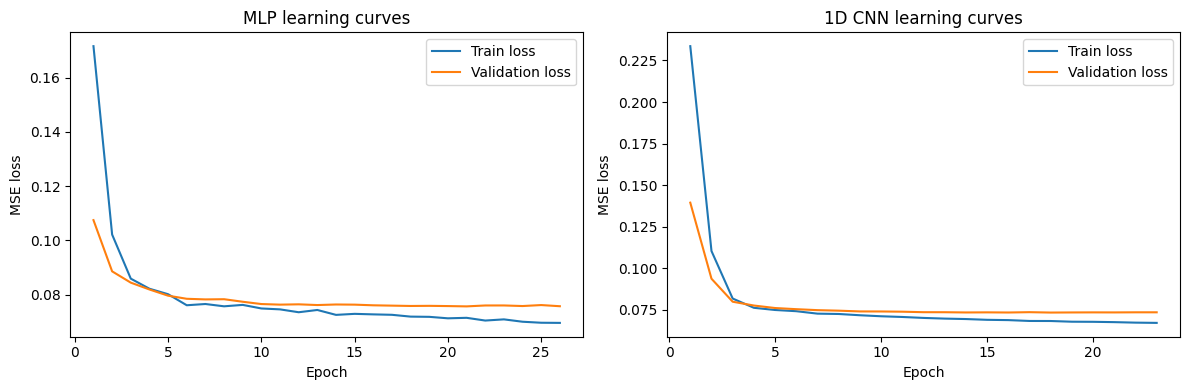

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, history, title in [
    (axes[0], mlp_histories[(best_units, best_lr)], "MLP learning curves"),
    (axes[1], cnn_histories[(best_1d_filters, best_1d_kernel)], "1D CNN learning curves")
]:
    ax.plot(np.arange(1, len(history["loss"]) + 1), history["loss"], label="Train loss")
    ax.plot(np.arange(1, len(history["val_loss"]) + 1), history["val_loss"], label="Validation loss")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE loss")
    ax.set_title(title)
    ax.legend()

plt.tight_layout()
plt.show()

## 7. Final refit and test evaluation
Hyperparameters and epochs are fixed from validation. Fit a new scaler on train + validation, train a fresh model on all development windows, and evaluate the observed test targets once.

In [16]:
dev = pd.concat([train, val])

final_scaler = StandardScaler()
dev_scaled = final_scaler.fit_transform(
    dev.to_numpy().reshape(-1, 1)
).ravel()

test_scaled_final = final_scaler.transform(
    test.to_numpy().reshape(-1, 1)
).ravel()

X_dev, y_dev = make_windows(dev_scaled, LOOKBACK)
X_test_final, y_test_final = make_windows(test_scaled_final, LOOKBACK)

X_test_final = X_test_final[test_observed]
y_test_final = y_test_final[test_observed]

test_actual = inverse_1d(y_test_final, final_scaler)
test_naive = inverse_1d(X_test_final[:, -1], final_scaler)

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

final_mlp = build_mlp(best_units, best_lr)

start = time.time()
final_mlp.fit(
    X_dev, y_dev,
    epochs=best_epochs_mlp,
    batch_size=32,
    shuffle=False,
    verbose=0
)
mlp_train_time = time.time() - start

mlp_pred = inverse_1d(final_mlp.predict(X_test_final, verbose=0).ravel(), final_scaler)

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

final_cnn = build_1d_cnn(best_1d_filters, best_1d_kernel)

start = time.time()
final_cnn.fit(
    X_dev[..., np.newaxis], y_dev,
    epochs=best_epochs_cnn,
    batch_size=32,
    shuffle=False,
    verbose=0
)
cnn_train_time = time.time() - start

cnn_pred = inverse_1d(final_cnn.predict(X_test_final[..., np.newaxis], verbose=0).ravel(), final_scaler)

In [17]:
def test_scores(name, pred, params, train_time):
    return {
        "Model": name,
        "Parameters": params,
        "Training time (s)": train_time,
        "MAE": mean_absolute_error(test_actual, pred),
        "RMSE": mean_squared_error(test_actual, pred) ** 0.5
    }

results_final = pd.DataFrame([
    test_scores("Naive", test_naive, 0, 0.0),
    test_scores("MLP", mlp_pred, final_mlp.count_params(), mlp_train_time),
    test_scores("1D CNN", cnn_pred, final_cnn.count_params(), cnn_train_time)
])

naive_mae = results_final.loc[0, "MAE"]
naive_rmse = results_final.loc[0, "RMSE"]
results_final["MAE improvement (%)"] = 100 * (naive_mae - results_final["MAE"]) / naive_mae
results_final["RMSE improvement (%)"] = 100 * (naive_rmse - results_final["RMSE"]) / naive_rmse

display(results_final.round(3))

,Model,Parameters,Training time (s),MAE,RMSE,MAE improvement (%),RMSE improvement (%)
0,Naive,0,0.000,11.958,22.152,0.000,0.000
1,MLP,833,190.002,12.008,21.499,-0.423,2.946
2,1D CNN,1601,248.047,11.954,21.674,0.026,2.159


In [18]:
assert X_train.shape[1] == LOOKBACK and X_val.shape[1] == LOOKBACK and X_test.shape[1] == LOOKBACK
assert train_raw.index.max() < val_raw.index.min() and val_raw.index.max() < test_raw.index.min()
assert np.isclose(scaler.mean_[0], train.mean())
assert len(test_actual) == len(mlp_pred) == len(cnn_pred) == len(test_naive)
print("Smoke test passed")

Smoke test passed


## 8. Conclusion and unresolved risk
**Conclusion.** At a one-hour horizon the naive forecast (repeat the last hour) is very hard to beat. On the test set it scores MAE 11.96 and RMSE 22.15 µg/m³. The MLP (32 units, learning rate 0.001) lowers RMSE by about 2.9 % and the 1D CNN (8 filters, kernel size 3) by about 2.2 %, but neither lowers MAE meaningfully (MLP −0.4 %, CNN +0.03 %). Both networks have many more parameters than the baseline and gain only a little.

**Unresolved risk.** The gains over naive are small, the validation winner (CNN) is not the test winner (MLP), and every result comes from a single training run with one seed. We cannot yet say that either network really beats the naive baseline or that one beats the other. Next step: repeat the fits with several seeds and compare the spread.